<a href="https://colab.research.google.com/github/badarintv-cloud/car-prices-pandas-analysis---Badari/blob/main/Badari_Narayanan_Car_Prices_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("car_prices.csv")

df.head()  # first 5 rows
print("Records:", len(df))
print("Shape (rows, columns):", df.shape)
print("Columns:", list(df.columns))
df.dtypes  # data types

Records: 558837
Shape (rows, columns): (558837, 16)
Columns: ['year', 'make', 'model', 'trim', 'body', 'transmission', 'vin', 'state', 'condition', 'odometer', 'color', 'interior', 'seller', 'mmr', 'sellingprice', 'saledate']


,0
year,int64
make,object
model,object
trim,object
body,object
transmission,object
vin,object
state,object
condition,float64
odometer,float64


              null_count  null_pct
transmission       65352     11.69
body               13195      2.36
condition          11820      2.12
trim               10651      1.91
model              10399      1.86
make               10301      1.84
color                749      0.13
interior             749      0.13
odometer              94      0.02
mmr                   38      0.01
saledate              12      0.00
sellingprice          12      0.00
vin                    4      0.00
year                   0      0.00
state                  0      0.00
seller                 0      0.00


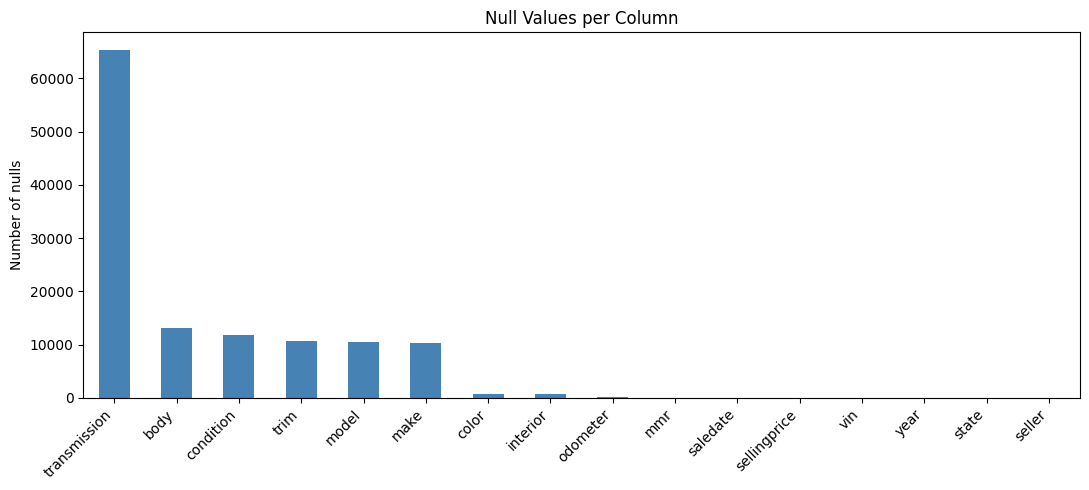

In [3]:
null_summary = pd.DataFrame({
    "null_count": df.isnull().sum(),
    "null_pct": (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values("null_count", ascending=False)
print(null_summary)

null_summary["null_count"].plot(kind="bar", figsize=(11, 5), color="steelblue")
plt.title("Null Values per Column")
plt.ylabel("Number of nulls")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [4]:
# 1. Remove 26 corrupted rows (columns shifted, VIN landed in 'state')
df = df[df["state"].astype(str).str.fullmatch(r"[a-z]{2}")].copy()

# 2. Standardise text and convert "—" placeholders to real nulls
text_cols = ["make", "model", "trim", "body", "transmission", "color", "interior", "seller"]
for c in text_cols:
    df[c] = df[c].str.strip().str.lower()
df[["color", "interior"]] = df[["color", "interior"]].replace("—", np.nan)

# 3. Drop rows missing fields that can't be guessed
df = df.dropna(subset=["make", "model", "sellingprice"])

# 4. Numeric columns: fill with median (robust to outliers)
for c in ["condition", "odometer", "mmr"]:
    df[c] = df[c].fillna(df[c].median())

# 5. Categorical columns: fill with "unknown"
for c in ["trim", "body", "transmission", "color", "interior", "vin", "saledate"]:
    df[c] = df[c].fillna("unknown")

print("Remaining nulls:", df.isnull().sum().sum())   # should be 0
print("Rows now:", len(df))

Remaining nulls: 0
Rows now: 548400


Rows missing make, model or selling price (about 2%) were dropped because they cannot be inferred. Numeric nulls (condition, odometer, mmr) were filled with the median because the distributions are skewed. Categorical nulls (transmission, trim, body, color, interior) were filled with “unknown” to avoid discarding about 12% of the data.

In [5]:
print("Duplicate records:", df.duplicated().sum())
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Duplicate records: 0
Rows after removing duplicates: 548400


Average, min and max price

In [6]:

print("Average:", round(df["sellingprice"].mean(), 2))
print("Minimum:", df["sellingprice"].min())
print("Maximum:", df["sellingprice"].max())

Average: 13689.29
Minimum: 1.0
Maximum: 230000.0


Unique colors

In [7]:
print(df["color"].unique())

['white' 'gray' 'black' 'red' 'silver' 'blue' 'brown' 'beige' 'purple'
 'burgundy' 'unknown' 'gold' 'yellow' 'green' 'charcoal' 'orange'
 'off-white' 'turquoise' 'pink' 'lime']


Unique brands and models

In [8]:
print("Unique brands:", df["make"].nunique())
print("Unique models:", df["model"].nunique())

Unique brands: 66
Unique models: 851


Cars with selling price > $165,000

In [9]:
df[df["sellingprice"] > 165000]

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
125095,2012,rolls-royce,ghost,base,sedan,automatic,sca664s58cux50727,fl,45.0,14316.0,black,beige,braman motorcars,154000.0,169500.0,Wed Jan 14 2015 01:40:00 GMT-0800 (PST)
344905,2014,ford,escape,titanium,suv,automatic,1fmcu9j98eua23833,mo,43.0,27802.0,green,tan,ford-lincoln dealer program,22800.0,230000.0,Wed Feb 25 2015 02:00:00 GMT-0800 (PST)
446949,2015,mercedes-benz,s-class,s65 amg,sedan,automatic,wddug7kb2fa102347,ca,41.0,5277.0,white,white,mercedes-benz usa,170000.0,173000.0,Thu May 21 2015 05:00:00 GMT-0700 (PDT)
538347,2012,rolls-royce,ghost,base,sedan,automatic,sca664s59cux50803,ca,44.0,5215.0,white,tan,financial services remarketing (bmw int),166000.0,167000.0,Thu Jun 18 2015 05:30:00 GMT-0700 (PDT)
545523,2013,rolls-royce,ghost,base,sedan,automatic,sca664s52dux52152,fl,42.0,7852.0,white,beige,flag/landrover southpointe,178000.0,171500.0,Wed Jun 17 2015 03:05:00 GMT-0700 (PDT)
548169,2011,ferrari,458 italia,base,coupe,automatic,zff67nfa1b0178698,fl,46.0,12116.0,red,black,platinum motor cars,182000.0,183000.0,Wed Jun 17 2015 03:40:00 GMT-0700 (PDT)
557570,2012,rolls-royce,ghost,ewb,sedan,automatic,sca664l50cux65625,ca,36.0,11832.0,white,black,bentley scottsdale,164000.0,169000.0,Thu Jun 18 2015 05:30:00 GMT-0700 (PDT)


Top 5 most frequently sold models

In [10]:
df["model"].value_counts().head(5)

,count
model,
altima,19349
f-150,14479
fusion,12945
camry,12549
escape,11893


Average selling price by brand

In [11]:
df.groupby("make")["sellingprice"].mean().sort_values(ascending=False).round(2)

,sellingprice
make,
rolls-royce,153488.24
ferrari,127210.53
lamborghini,112625.00
bentley,74367.67
airstream,71000.00
...,...
dodge tk,550.00
geo,528.95
dot,500.00


Minimum selling price per interior

In [12]:
df.groupby("interior")["sellingprice"].min()

,sellingprice
interior,
beige,100.0
black,1.0
blue,150.0
brown,200.0
burgundy,175.0
gold,250.0
gray,1.0
green,100.0
off-white,900.0


Highest odometer reading per year, highest to lowest

In [13]:
df.groupby("year")["odometer"].max().sort_values(ascending=False)

,odometer
year,
1997,999999.0
1998,999999.0
1999,999999.0
1996,999999.0
1993,999999.0
2009,999999.0
2012,999999.0
2008,999999.0
2007,999999.0


Car age column (current year = 2025)

In [14]:
df["car_age"] = 2025 - df["year"]
df[["year", "car_age"]].head()

,year,car_age
0,2015,10
1,2015,10
2,2014,11
3,2015,10
4,2014,11


Condition >= 48 and odometer > 90000

In [15]:
count = ((df["condition"] >= 48) & (df["odometer"] > 90000)).sum()
print("Number of cars:", count)

Number of cars: 725


State with consistently higher prices for newer cars (year > 2013)

In [16]:
newer = df[df["year"] > 2013]
state_year = newer.groupby(["state", "year"])["sellingprice"].agg(["mean", "count"]).reset_index()
state_year = state_year[state_year["count"] >= 30]      # ignore tiny samples
pivot = state_year.pivot(index="state", columns="year", values="mean").dropna()

print(pivot.round(0).sort_values(2015, ascending=False).head(5))
print(pivot.rank(ascending=False).sort_values([2014, 2015]).head(3))   # rank 1 in both years = consistent

year      2014     2015
state                  
oh     25903.0  32693.0
nj     21952.0  32603.0
pa     21455.0  28684.0
co     19690.0  27879.0
tn     21356.0  27790.0
year   2014  2015
state            
oh      1.0   1.0
nj      2.0   2.0
pa      3.0   3.0


Makes having the lowest average price - Excellent condition


In [17]:
threshold = df["condition"].quantile(0.8)
excellent = df[df["condition"] >= threshold]
value = excellent.groupby("make")["sellingprice"].agg(["mean", "count"])
value = value[value["count"] >= 30].sort_values("mean")     # min 30 listings so tiny makes don't win
value.head(5).round(2)

,mean,count
make,,
saturn,5700.41,123
smart,6835.76,158
pontiac,7686.82,148
mercury,9022.16,97
fiat,11655.29,208


Task 3

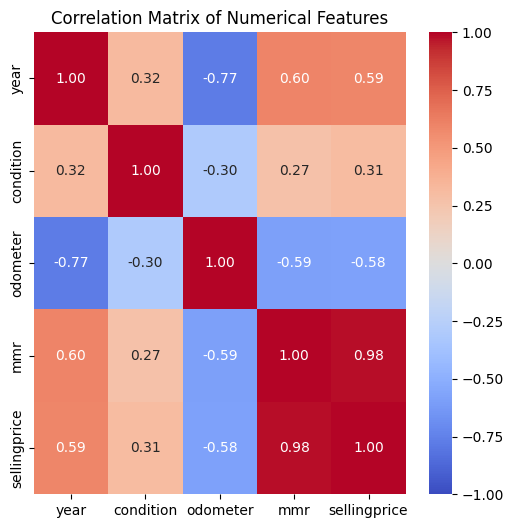

In [18]:
num_cols = ["year", "condition", "odometer", "mmr", "sellingprice"]
plt.figure(figsize=(6, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Numerical Features")
plt.show()

The mmr has a strong correlation with selling price (0.98), so the market estimate is a near-perfect predictor. Year (0.59) and odometer (−0.58) are the next strongest.
Condition has a weaker but positive link (0.31).

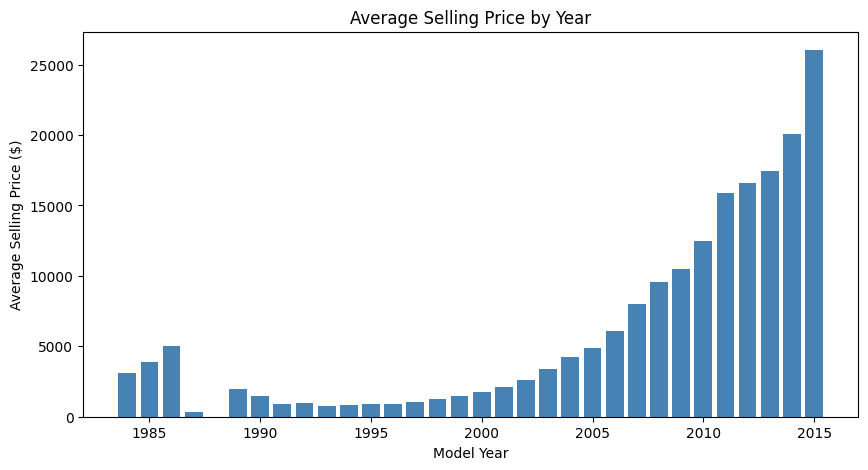

In [19]:
avg_year = df.groupby("year")["sellingprice"].mean()
plt.figure(figsize=(10, 5))
plt.bar(avg_year.index, avg_year.values, color="steelblue")
plt.title("Average Selling Price by Year")
plt.xlabel("Model Year"); plt.ylabel("Average Selling Price ($)")
plt.show()

Prices rise steadily with model year and the climb steepens after 2008. Very old years  have only 1 to 6 cars each, so those bars aren’t reliable. The 2015 bar rests on far fewer cars than 2012 to 2014.

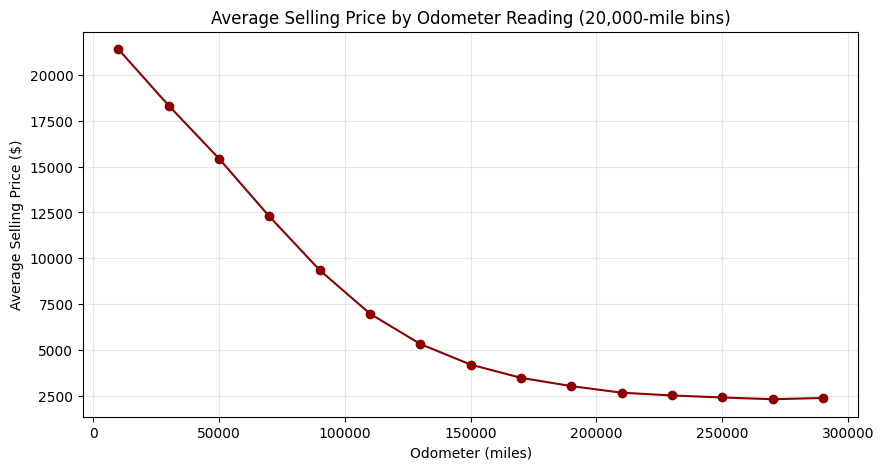

In [20]:
o = df[df["odometer"] < 500000].copy()          # remove 999,999 placeholder values
o["odo_bin"] = pd.cut(o["odometer"], bins=range(0, 320000, 20000), right=False)
avg_odo = o.groupby("odo_bin", observed=True)["sellingprice"].mean()
x = [iv.mid for iv in avg_odo.index]

plt.figure(figsize=(10, 5))
plt.plot(x, avg_odo.values, marker="o", color="darkred")
plt.title("Average Selling Price by Odometer Reading (20,000-mile bins)")
plt.xlabel("Odometer (miles)"); plt.ylabel("Average Selling Price ($)")
plt.grid(alpha=0.3)
plt.show()

Price falls steadily as mileage rises. After about 200K miles the curve flattens.

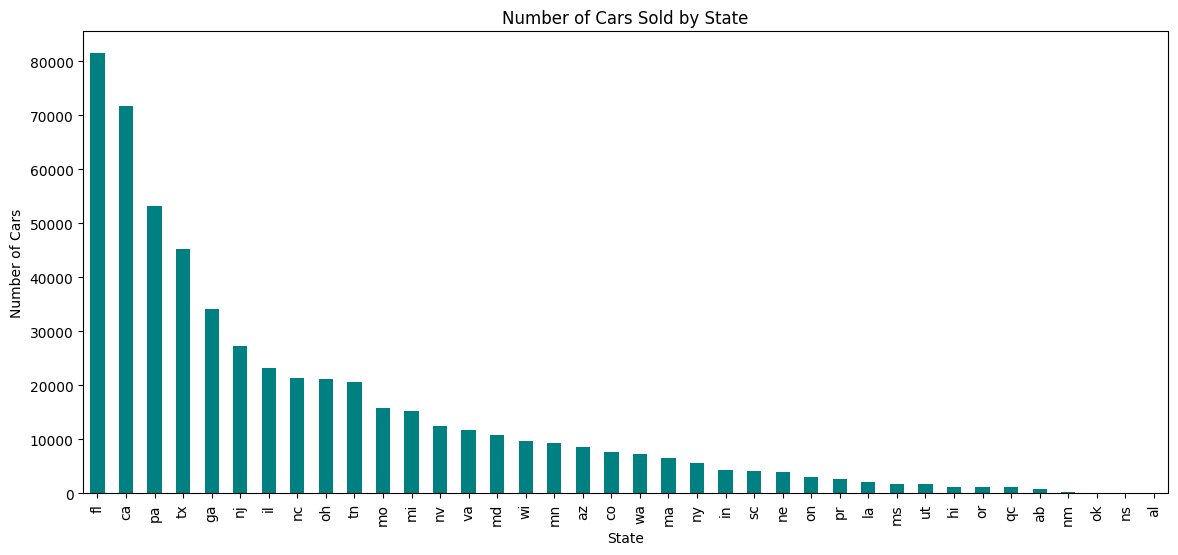

state
fl    81480
ca    71658
pa    53154
Name: count, dtype: int64


In [21]:
state_counts = df["state"].value_counts()
plt.figure(figsize=(14, 6))
state_counts.plot(kind="bar", color="teal")
plt.title("Number of Cars Sold by State")
plt.xlabel("State"); plt.ylabel("Number of Cars")
plt.show()
print(state_counts.head(3))

The top three states are Florida,California and Pennsylvania. Sales volume drops sharply after the top four states.

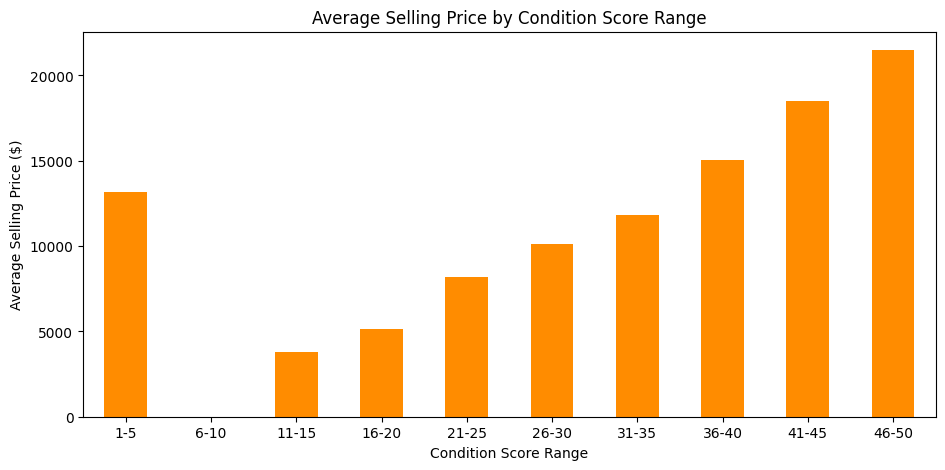

In [22]:
labels5 = [f"{i+1}-{i+5}" for i in range(0, 50, 5)]
df["cond_5"] = pd.cut(df["condition"], bins=range(0, 55, 5), labels=labels5)
avg_cond = df.groupby("cond_5", observed=False)["sellingprice"].mean()

plt.figure(figsize=(11, 5))
avg_cond.plot(kind="bar", color="darkorange")
plt.title("Average Selling Price by Condition Score Range")
plt.xlabel("Condition Score Range"); plt.ylabel("Average Selling Price ($)")
plt.xticks(rotation=0)
plt.show()

From the 11–15 range upward, price rises consistently with condition.
from (11–15) to (46–50)and the 6–10 range is empty.

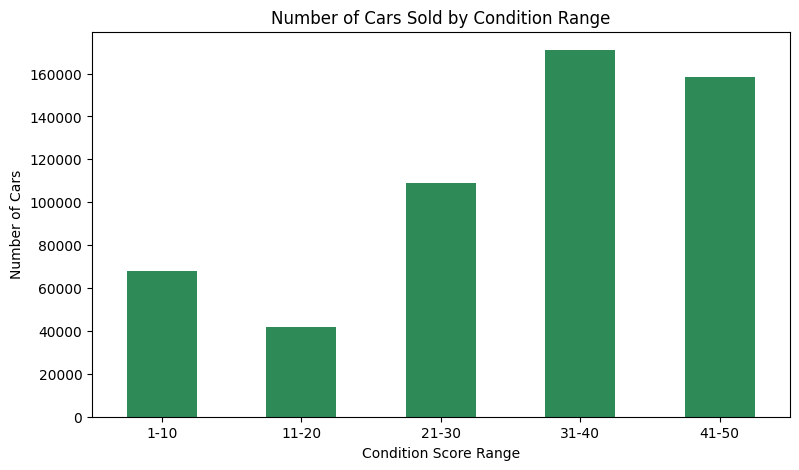

In [23]:
labels10 = ["1-10", "11-20", "21-30", "31-40", "41-50"]
df["cond_10"] = pd.cut(df["condition"], bins=range(0, 60, 10), labels=labels10)
cond_counts = df["cond_10"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
cond_counts.plot(kind="bar", color="seagreen")
plt.title("Number of Cars Sold by Condition Range")
plt.xlabel("Condition Score Range"); plt.ylabel("Number of Cars")
plt.xticks(rotation=0)
plt.show()

Most cars fall in the 31–40 range. and 41–50, so the majority are in good condition. Very few cars sit in the 11–20 range.

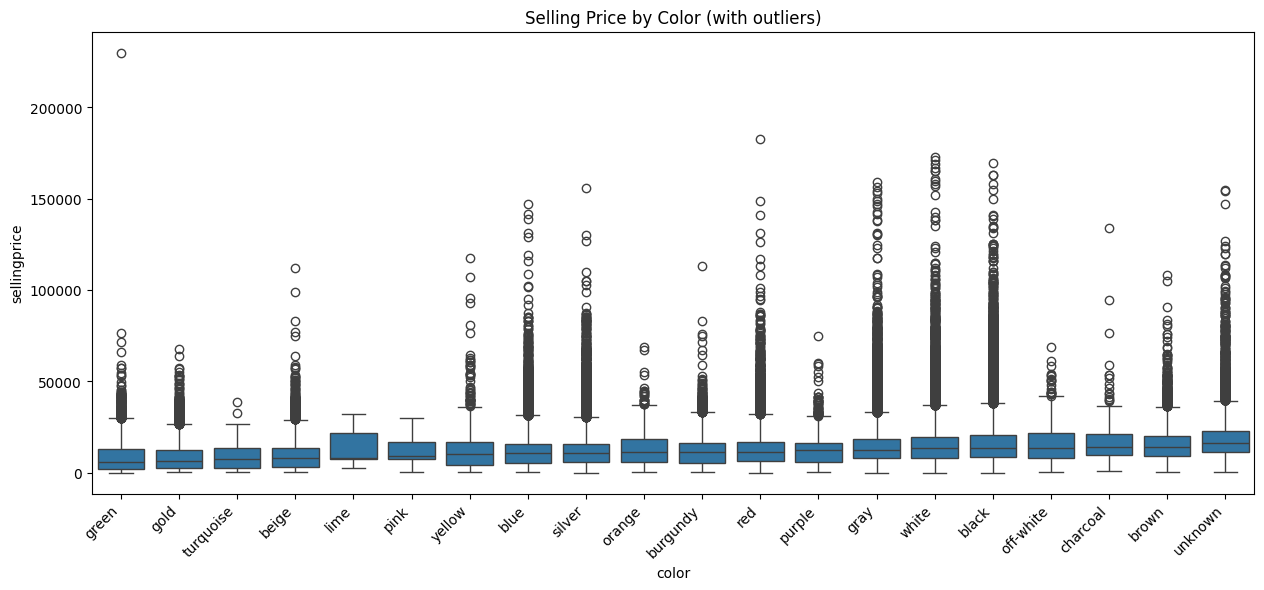

Rows removed as outliers: 16060


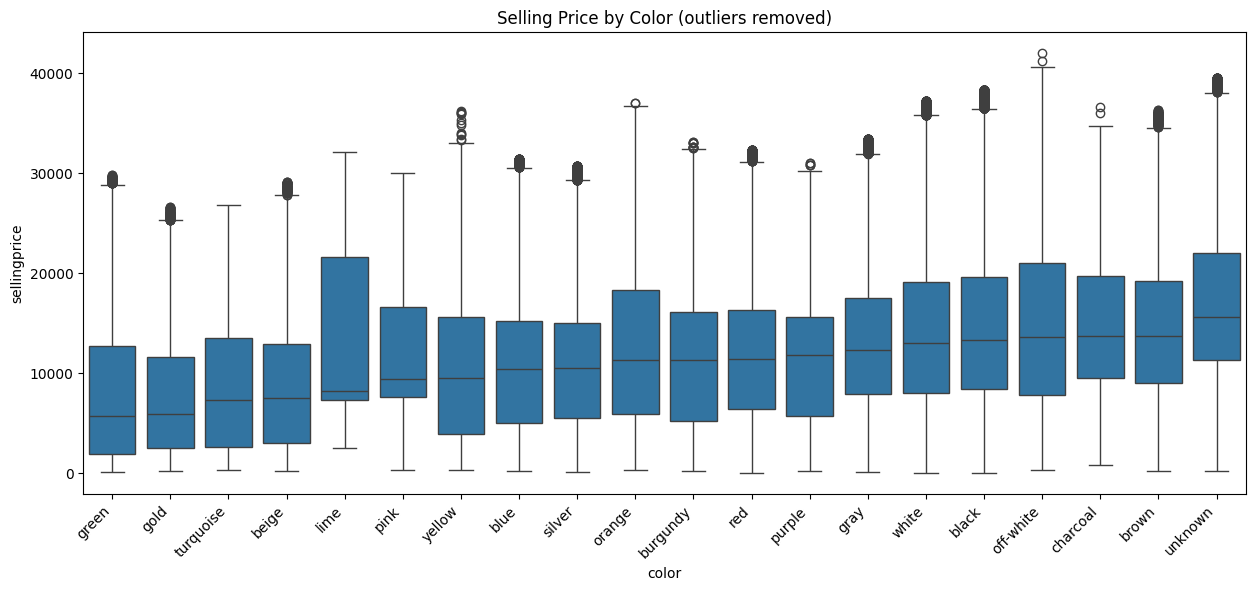

In [24]:
order = df.groupby("color")["sellingprice"].median().sort_values().index

# Before removing outliers
plt.figure(figsize=(15, 6))
sns.boxplot(data=df, x="color", y="sellingprice", order=order)
plt.title("Selling Price by Color (with outliers)")
plt.xticks(rotation=45, ha="right")
plt.show()

# Remove outliers using the IQR rule within each color
q1 = df.groupby("color")["sellingprice"].transform(lambda s: s.quantile(0.25))
q3 = df.groupby("color")["sellingprice"].transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
df_clean = df[(df["sellingprice"] >= q1 - 1.5 * iqr) & (df["sellingprice"] <= q3 + 1.5 * iqr)]
print("Rows removed as outliers:", len(df) - len(df_clean))

# After removing outliers
plt.figure(figsize=(15, 6))
sns.boxplot(data=df_clean, x="color", y="sellingprice", order=order)
plt.title("Selling Price by Color (outliers removed)")
plt.xticks(rotation=45, ha="right")
plt.show()

Every color has a long tail of high-priced outliers luxury and exotic cars. Medians range from green and gold up to brown and charcoal. Black and white, the most common colors, sit near the top. The “unknown” group has the highest median.
After removing outliers with the IQR rule, the boxes become easier to compare. Rare colors like lime and pink have too few listings hence no conclusions.